# Fit a Sérsic galaxy with pixel covariance

Fit one 41×41 mock image with diagonal ERR and finite pixel covariance. Both fits use the same PSF, marginal ERR and Gaussian background prior. Fit the half-light radius, total flux and constant background. Fix the Sérsic index and geometry to isolate the noise-model comparison and use the package's fixed-$n$ inference API.

Install the released package from PyPI before running this notebook. This example was prepared for `jwst-psfmc` 0.4.0. Select the same Python environment as the notebook kernel.

```bash
python -m pip install "jwst-psfmc[notebooks]==0.4.0"
```

## 1. Set up and verify the mock renderer

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.stats import sigma_clip
from IPython.display import Markdown, display
from scipy.signal import convolve2d, correlate2d
from scipy.integrate import quad_vec
from scipy.special import gamma, gammaincinv, ndtr

from jwst_psfmc import (
    CompositeModel, ConstantBackground, Normal, Parameter, ParameterSet, PSFOperator,
    PSFSpec, RenderContext, SersicSource, Uniform, evaluate_model_fit,
    optimize_model_fit, prepare_model_fitting, prepare_noise,
)

shape = (41, 41)
psf_sigma_x, psf_sigma_y = 0.90, 1.05
pixel_err = 0.0012
err = np.full(shape, pixel_err)

def make_context(shape, oversamp):
    grid = np.arange(-5 * oversamp, 5 * oversamp + 1) / oversamp

    def pixel_response(sigma):
        return ndtr((grid + 0.5) / sigma) - ndtr((grid - 0.5) / sigma)

    psf = PSFSpec(np.outer(pixel_response(psf_sigma_y), pixel_response(psf_sigma_x)),
                  "effective", 1 / oversamp, (5 * oversamp, 5 * oversamp),
                  "analytic unit-flux Gaussian pixel response")
    operator = PSFOperator(psf, oversamp=oversamp, max_offset=0.5, max_source_cells=7_000_000)
    return RenderContext(shape, psf_operator=operator)

source = SersicSource("galaxy")
model = CompositeModel([source, ConstantBackground("sky")])
geometry = {"galaxy.n": 4.0, "galaxy.dx": 0.18, "galaxy.dy": -0.26, "galaxy.q": 0.68, "galaxy.pa": 27.0}
truth = {**geometry, "galaxy.re": 10.0, "galaxy.flux": 1.0, "sky.level": 0.003}

smoothing = np.array([[0.10, 0.27, 0.10], [0.27, 1.00, 0.27], [0.10, 0.27, 0.10]])
smoothing /= np.linalg.norm(smoothing)
kernel = correlate2d(smoothing, smoothing, mode="full")
covariance_options = dict(backend="dense", err=err, kernel=kernel, boundary="finite",
                          max_dense_bytes=192 * 1024**2)


For an independent reference, integrate the continuous elliptical Sérsic profile in polar coordinates against the analytic Gaussian response integrated over each output pixel. This uses neither the source lattice nor the tabulated ePSF. Check angular convergence, then evaluate $\epsilon=\sqrt{(m-m_\mathrm{ref})^T C^{-1}(m-m_\mathrm{ref})}$ using the full finite-boundary covariance. Set the input flux for peak S/N 50 using the reference image. Adopt 12× for the source grid and ePSF table when $\epsilon$ meets the 0.1 budget. This check applies at the mock input geometry. Other radii and empirical PSFs need their own validation.

In [2]:
def continuous_reference(angles):
    # The enclosed Sérsic flux is a Gamma(2n, 1) CDF in u = b_n (r / Re)^(1/n).
    n, radius = truth["galaxy.n"], truth["galaxy.re"]
    q, pa = truth["galaxy.q"], np.deg2rad(truth["galaxy.pa"])
    theta = np.arange(angles) * (2 * np.pi / angles)
    ex = np.cos(theta) * np.cos(pa) - q * np.sin(theta) * np.sin(pa)
    ey = np.cos(theta) * np.sin(pa) + q * np.sin(theta) * np.cos(pa)
    x = (np.arange(shape[1]) - (shape[1] - 1) / 2 - truth["galaxy.dx"])[:, None]
    y = (np.arange(shape[0]) - (shape[0] - 1) / 2 - truth["galaxy.dy"])[:, None]
    b_n = gammaincinv(2 * n, 0.5)
    norm = angles * gamma(2 * n)

    def response(u):
        r = radius * (u / b_n)**n
        dx, dy = x - r * ex, y - r * ey
        wx = ndtr((dx + 0.5) / psf_sigma_x) - ndtr((dx - 0.5) / psf_sigma_x)
        wy = ndtr((dy + 0.5) / psf_sigma_y) - ndtr((dy - 0.5) / psf_sigma_y)
        return (wy @ wx.T) * (u**(2 * n - 1) * np.exp(-u) / norm)

    return quad_vec(response, 0, 80, epsabs=2e-10, epsrel=2e-10)[0]

reference = continuous_reference(1024)
truth["galaxy.flux"] = 50 * pixel_err / reference.max()
reference *= truth["galaxy.flux"]
metric = prepare_noise(reference, **covariance_options)
reference_change = np.linalg.norm(metric.whiten(reference - truth["galaxy.flux"] * continuous_reference(512)))
assert reference_change < 0.005
rows = ["| Source and ePSF sampling | Covariance-weighted ε |", "| ---: | ---: |"]
for oversamp in (4, 8, 12):
    context = make_context(shape, oversamp)
    signal = source.render(truth, context)
    epsilon = np.linalg.norm(metric.whiten(signal - reference))
    rows.append(f"| {oversamp}× | {epsilon:.3f} |")
assert epsilon < 0.1
display(Markdown(f"The angular-refinement difference is {reference_change:.2e} in the same norm.\n\n" + "\n".join(rows)))

The angular-refinement difference is 6.41e-14 in the same norm.

| Source and ePSF sampling | Covariance-weighted ε |
| ---: | ---: |
| 4× | 0.351 |
| 8× | 0.106 |
| 12× | 0.038 |

## 2. Measure the background prior on the parent image

The 41×41 stamp is the center of a 201×201 mock. Seed 75 illustrates a particular realization. The parent extends its correlated noise beyond the fit. Use the first five consecutive 10-pixel running windows whose radial median lies within half the running RMS of a provisional outer sky. Start a 20-pixel annulus 10 pixels beyond the first passing center.

For your own image, supply an annulus mask that excludes the target, neighbors and bad pixels and leaves a gap from the likelihood pixels. The helper clips deviations beyond 3σ from the median, using the standard deviation and up to ten iterations. It reports the mean, median and pixel RMS of the retained values. The prior width is the statistical error of the mean $\sqrt{w^T C w}$ conditional on the retained mask, with $w=1/N$ there. With $C_{ij}=\mathrm{ERR}_i\rho_{ij}\mathrm{ERR}_j$, convolving the ERR-weighted mask applies the correlation kernel without a dense parent matrix. The mock diagnoses residual wings using the known source. Sky measured outside the stamp helps constrain the fitted profile, whose total flux extends beyond the fitted pixels. In this mock, clipping removes 34 pixels and increases the absolute offset from the input sky by about 2.8e-06 µJy/pixel.

In [3]:
parent_shape = (201, 201)
parent_err = np.full(parent_shape, pixel_err)
offset = (parent_shape[0] - shape[0]) // 2
stamp = np.s_[offset:offset+shape[0], offset:offset+shape[1]]
seed = 75
stamp_white = np.random.default_rng(seed).standard_normal(tuple(np.array(shape) + 2))
white = np.random.default_rng(2718276).standard_normal(tuple(np.array(parent_shape) + 2))
white[offset:offset+stamp_white.shape[0], offset:offset+stamp_white.shape[1]] = stamp_white
parent_source = source.render(truth, make_context(parent_shape, 12))
parent_image = parent_source + truth["sky.level"] + parent_err * convolve2d(white, smoothing, mode="valid")
image = parent_image[stamp]
np.testing.assert_allclose(parent_source[stamp], signal, rtol=0, atol=1e-12)

y, x = np.indices(parent_shape) - parent_shape[0] // 2
radius = np.hypot(x, y)
profile = np.array([parent_image[(i <= radius) & (radius < i+1)].mean() for i in range(100)])
outer_sky = parent_image[(75 <= radius) & (radius < 100)].mean()
# The center of the outermost correlated stamp pixel lies within this radius.
support = np.array(kernel.shape) // 2
first_ring = int(np.floor(np.linalg.norm((np.array(shape) - 1) // 2 + support))) + 1
starts = np.arange(first_ring, 75 - 10 + 1)
windows = np.lib.stride_tricks.sliding_window_view(profile, 10)[starts]
median = np.median(windows, axis=1)
rms = np.sqrt(np.mean((windows - median[:, None])**2, axis=1))
passes = np.abs(median - outer_sky) < 0.5 * rms
runs = np.flatnonzero(np.lib.stride_tricks.sliding_window_view(passes, 5).all(axis=1))
if not runs.size:
    raise ValueError("No sustained sky plateau in the available profile")
inner = starts[runs[0]] + 5 + 10  # Window center, then the 10-pixel gap.
outer = inner + 20
assert outer <= 100
annulus = (inner <= radius) & (radius < outer)

In [4]:
def sky_prior_from_mask(data, error, mask, correlation_kernel, clip_sigma=3.0):
    """Measure sky statistics and the mean error for the retained mask."""
    valid = mask & np.isfinite(data) & np.isfinite(error) & (error > 0)
    if clip_sigma is not None:
        clipped = sigma_clip(data[valid], sigma=clip_sigma, maxiters=10, cenfunc="median", stdfunc="std")
        valid[valid] = ~np.ma.getmaskarray(clipped)
    count = valid.sum()
    if count < 2:
        raise ValueError("At least two valid sky pixels are required")
    weights_err = np.where(valid, error, 0.0) / count
    variance = np.sum(weights_err * convolve2d(weights_err, correlation_kernel, mode="same"))
    pixels = data[valid]
    return pixels.mean(), np.median(pixels), np.sqrt(variance), pixels.std(ddof=1), valid

unclipped = sky_prior_from_mask(parent_image, parent_err, annulus, kernel, clip_sigma=None)
clipped = sky_prior_from_mask(parent_image, parent_err, annulus, kernel)
sky_mean, sky_median, sky_sigma, sky_rms, sky_mask = clipped
touches_sky = convolve2d(sky_mask.astype(int), (kernel != 0).astype(int), mode="same")
assert not touches_sky[stamp].any()
rows = [
    "| Sky statistic | Pixels | Mean | Median | Pixel RMS | Mean error | Mean − input |",
    "| --- | ---: | ---: | ---: | ---: | ---: | ---: |",
]
for name, (mean, median, sigma, rms, mask) in (("Unclipped", unclipped), ("3σ clipped", clipped)):
    rows.append(f"| {name} | {mask.sum():,} | {1e3*mean:.4f} | {1e3*median:.4f} | "
                f"{1e3*rms:.4f} | {1e3*sigma:.4f} | {1e3*(mean-truth['sky.level']):+.4f} |")
display(Markdown(f"Sky annulus {inner}–{outer} pix. Flux units are $10^{{-3}}$ µJy/pixel.\n\n"
                 + "\n".join(rows)))
wings = parent_source[sky_mask].mean()
print(f"Injected wings: {wings/sky_sigma:.2f} × mean σ. Fraction of input flux on stamp: "
      f"{signal.sum()/truth['galaxy.flux']:.1%}.")

parameters = ParameterSet([
    Parameter("galaxy.re", initial=8.0, prior=Uniform(1.25, 32.0)),
    Parameter("galaxy.flux", initial=3.0, prior=Uniform(0.0, 30.0)),
    Parameter("sky.level", initial=sky_mean, prior=Normal(sky_mean, sky_sigma)),
    *[Parameter(name, fixed=value) for name, value in geometry.items()],
])

Sky annulus 56–76 pix. Flux units are $10^{-3}$ µJy/pixel.

| Sky statistic | Pixels | Mean | Median | Pixel RMS | Mean error | Mean − input |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Unclipped | 8,280 | 2.9899 | 3.0106 | 1.1979 | 0.0279 | -0.0101 |
| 3σ clipped | 8,246 | 2.9871 | 3.0093 | 1.1738 | 0.0279 | -0.0129 |

Injected wings: 0.48 × mean σ. Fraction of input flux on stamp: 76.5%.


## 3. Fit with each noise model

Diagonal ERR treats the pixels as independent. The Covariance model includes finite-boundary covariance between pixels inside the stamp. The optimizer returns a maximum-a-posteriori (MAP) point estimate for each model.

In [5]:
noise_options = {
    "Diagonal ERR": dict(backend="diagonal", err=err),
    "Covariance": covariance_options,
}

results, fits, map_vectors = {}, {}, {}
for name, options in noise_options.items():
    fit = prepare_model_fitting(image, model, parameters, context=context,
                                noise_options=options, data_unit="uJy/pixel")
    optimum = optimize_model_fit(fit, objective="map")
    if not optimum.best.success:
        raise RuntimeError(f"{name}: {optimum.best.message}")
    fits[name] = fit
    map_vectors[name] = optimum.best.sample_vector
    results[name] = evaluate_model_fit(fit, map_vectors[name], decompose=True)

## 4. Compare the fitted parameters and residuals

Report the MAP estimate and an approximate 1σ uncertainty from the inverse Hessian of the negative log posterior. The Hessian includes the likelihood and background prior. Its inverse keeps the covariances between radius, flux and sky. These are local Gaussian errors near the MAP.

The parameter plot shows Measurement / Input. Radius and flux share a scale. The background panel fits its own error bars. The dotted line at 1 marks the simulated input. The Diagonal ERR map divides the image residual by the marginal ERR. The Covariance map shows the Cholesky-whitened residual in the original pixel order. Whitening mixes pixels, so the two panels have separate colorbars.

MAP ± approximate 1σ.

| Model | Re (pix) | Total flux (µJy) | bkg (10⁻³ µJy/pixel) |
| --- | ---: | ---: | ---: |
| Input | 10.00 | 3.652 | 3.0000 |
| Diagonal ERR | 10.64 ± 0.30 | 3.827 ± 0.089 | 2.9832 ± 0.0236 |
| Covariance | 10.36 ± 0.54 | 3.758 ± 0.162 | 2.9873 ± 0.0266 |

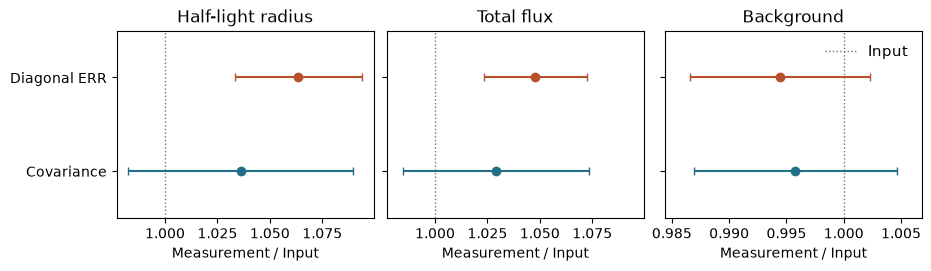

In [6]:
def local_errors(fit, center, steps):
    """Compute the local Gaussian errors in physical units for linear parameters."""
    def loss(offset):
        return -evaluate_model_fit(fit, center + steps * offset)["log_posterior"]

    basis = np.eye(len(center))
    hessian = np.empty((len(center), len(center)))
    at_center = loss(np.zeros_like(center))
    for i, ei in enumerate(basis):
        hessian[i, i] = loss(ei) + loss(-ei) - 2 * at_center
        for j, ej in enumerate(basis[:i]):
            mixed = (loss(ei + ej) - loss(ei - ej) - loss(-ei + ej) + loss(-ei - ej)) / 4
            hessian[i, j] = hessian[j, i] = mixed
    np.linalg.cholesky(hessian)
    return steps * np.sqrt(np.diag(np.linalg.solve(hessian, basis)))

names = ("galaxy.re", "galaxy.flux", "sky.level")
steps = np.array([0.02, 0.005, 0.1 * sky_sigma])
errors = {}
for name, fit in fits.items():
    assert fit.parameters.free_names == names
    errors[name] = local_errors(fit, map_vectors[name], steps)
    np.testing.assert_allclose(errors[name], local_errors(fit, map_vectors[name], steps / 2), rtol=.01)

scale = np.array([1, 1, 1e3])
input_values = np.array([truth[key] for key in names])
rows = [
    "| Model | Re (pix) | Total flux (µJy) | bkg (10⁻³ µJy/pixel) |",
    "| --- | ---: | ---: | ---: |",
    f"| Input | {input_values[0]:.2f} | {input_values[1]:.3f} | {1e3*input_values[2]:.4f} |",
]
for name, result in results.items():
    fitted = [result["values"][key] for key in names]
    columns = [f"{value:.{digits}f} ± {error:.{digits}f}"
               for value, error, digits in zip(scale * fitted, scale * errors[name], (2, 3, 4))]
    rows.append(f"| {name} | " + " | ".join(columns) + " |")
display(Markdown("MAP ± approximate 1σ.\n\n" + "\n".join(rows)))

fig, axes = plt.subplots(1, 3, figsize=(9.2, 2.6), sharey=True, layout="constrained")
axes[1].sharex(axes[0])
colors = {"Diagonal ERR": "#b8502c", "Covariance": "#226f87"}
titles = ("Half-light radius", "Total flux", "Background")
for j, (ax, title) in enumerate(zip(axes, titles)):
    ax.axvline(1, color=".45", ls=":", lw=1, label="Input")
    for i, (name, result) in enumerate(results.items()):
        ratio = result["values"][names[j]] / input_values[j]
        ax.errorbar(ratio, i, xerr=errors[name][j] / input_values[j], fmt="o",
                    color=colors[name], capsize=3)
    ax.set(title=title, xlabel="Measurement / Input", ylim=(1.5, -.5))
axes[0].set_yticks(np.arange(len(results)), labels=results.keys())
# Scale the background panel to its own uncertainty intervals and input reference.
bg_centers = np.array([result["values"]["sky.level"] for result in results.values()]) / input_values[2]
bg_errors = np.array([error[2] for error in errors.values()]) / input_values[2]
left = min(1, np.min(bg_centers - bg_errors))
right = max(1, np.max(bg_centers + bg_errors))
padding = .12 * (right - left)
axes[2].set_xlim(left - padding, right + padding)
axes[2].xaxis.set_major_formatter("{x:.3f}")
axes[2].legend(loc="upper right", frameon=False, fontsize=11)
plt.show()

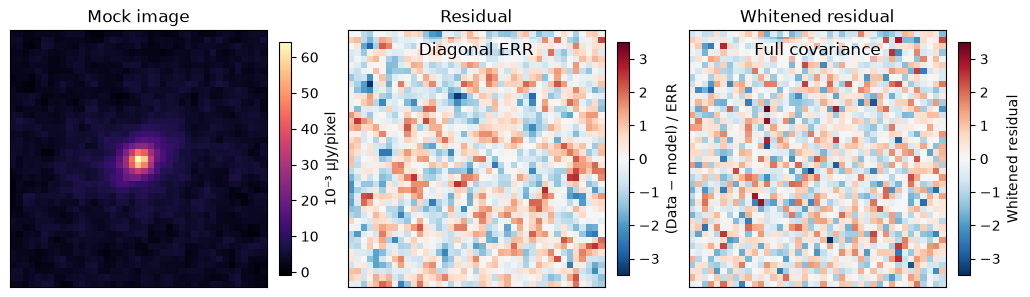

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10.2, 3.1), layout="constrained")
sci = axes[0].imshow(1e3 * image, origin="lower", cmap="magma")
axes[0].set_title("Mock image")
fig.colorbar(sci, ax=axes[0], label="10⁻³ µJy/pixel", shrink=.79)
diagonal = axes[1].imshow(results["Diagonal ERR"]["standardized_residual"], origin="lower",
                          cmap="RdBu_r", vmin=-3.5, vmax=3.5)
axes[1].set_title("Residual")
fig.colorbar(diagonal, ax=axes[1], label="(Data − model) / ERR", shrink=.79)

whitened = results["Covariance"]["whitened_residual"].reshape(shape)
covariance = axes[2].imshow(whitened, origin="lower", cmap="RdBu_r", vmin=-3.5, vmax=3.5)
axes[2].set_title("Whitened residual")
fig.colorbar(covariance, ax=axes[2], label="Whitened residual", shrink=.79)
for ax, label in zip(axes[1:], ("Diagonal ERR", "Full covariance")):
    ax.text(.5, .955, label, transform=ax.transAxes, ha="center", va="top",
            fontsize=12, color="black",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.5, pad=2))
for ax in axes:
    ax.set(xticks=[], yticks=[])
plt.show()

## 5. Check the reported errors over repeated noise realizations

Repeat the experiment for one fixed source using the independent reference as the noiseless signal, 200 correlated noise draws and 200 independent Gaussian sky measurements centered on the input sky with the measured annulus uncertainty. Each pair of fits shares its image and external sky draw. This tests calibration for a known sky-measurement error and holds the annulus selection fixed.

At each grid radius, solve for total flux and sky analytically under the Gaussian sky prior. Use a local quadratic interpolation of the profiled $\chi^2$ to estimate the radius and its curvature error. Empirical scatter is the sample standard deviation of the 200 fitted radii around their own mean, computed with `r.std(ddof=1)`. Compare that scatter with the typical reported uncertainty and the fraction of intervals containing the input radius. The repeat experiment measures how the uncertainty reported for one image compares with the scatter across noise draws.

| Model | Empirical radius scatter (pix) | Median reported 1σ (pix) | 1σ coverage |
| --- | ---: | ---: | ---: |
| Diagonal ERR | 0.497 | 0.284 | 40.5% |
| Covariance | 0.498 | 0.512 | 70.0% |

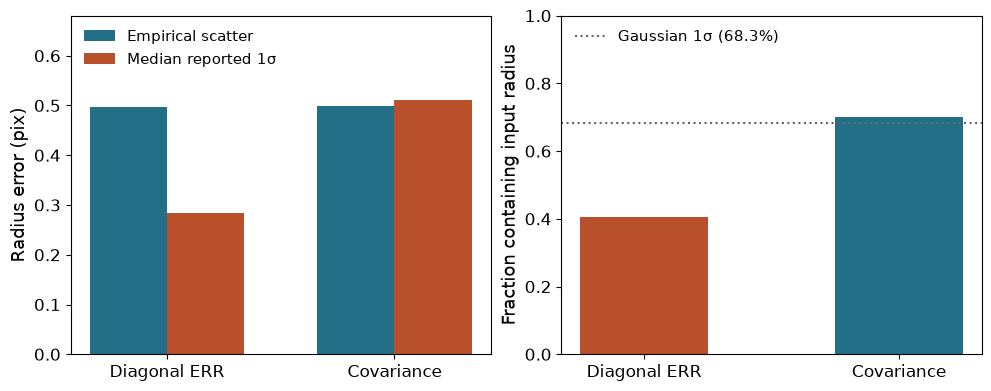

The radius scatter is 0.497 and 0.498 pix for Diagonal ERR and Covariance. Their reported 1σ intervals contain the input in 40.5% and 70.0% of trials, respectively. With 200 trials, the binomial standard error near 68% coverage is about 3.3 percentage points.

In [8]:
rng = np.random.default_rng(24681)
n_trials = 200
sky_draws = rng.normal(truth["sky.level"], sky_sigma, n_trials)
mock_images = np.stack([
    reference + truth["sky.level"] + err * convolve2d(
        rng.standard_normal(tuple(np.array(shape) + 2)), smoothing, mode="valid")
    for _ in range(n_trials)
])
r_grid = np.linspace(6, 14, 161)
dr = r_grid[1] - r_grid[0]
templates = np.stack([
    source.render({**truth, "galaxy.re": r, "galaxy.flux": 1.0}, context) for r in r_grid
])

def repeated_radius_fits(noise):
    unit = np.stack([noise.whiten(template) for template in templates])
    sky = noise.whiten(np.ones(shape))
    data = np.stack([noise.whiten(mock) for mock in mock_images])
    # Gaussian background measurement contributes a row with no source flux.
    sky_info = sky @ sky + sky_sigma**-2
    sky_data = data @ sky + sky_draws / sky_sigma**2
    cross = unit @ sky
    source_info = np.einsum("ij,ij->i", unit, unit) - cross**2 / sky_info
    projection = data @ unit.T - sky_data[:, None] * cross / sky_info
    flux = projection / source_info
    assert np.all((flux > 0) & (flux < 30))
    # Profile chi-square up to terms constant in radius.
    chi2 = -projection * flux
    k = chi2.argmin(axis=1)
    assert np.all((k > 0) & (k < len(r_grid) - 1))
    left, center, right = chi2[np.arange(n_trials)[:, None], k[:, None] + [-1, 0, 1]].T
    curvature = left + right - 2 * center
    assert np.all(curvature > 0)
    best_radius = r_grid[k] + 0.5 * dr * (left - right) / curvature
    return best_radius, dr * np.sqrt(2 / curvature)

calibration = {name: repeated_radius_fits(fit.noise) for name, fit in fits.items()}
rows = ["| Model | Empirical radius scatter (pix) | Median reported 1σ (pix) | 1σ coverage |",
        "| --- | ---: | ---: | ---: |"]
for name, (r, sigma) in calibration.items():
    fraction = np.mean(np.abs(r - truth["galaxy.re"]) <= sigma)
    rows.append(f"| {name} | {r.std(ddof=1):.3f} | {np.median(sigma):.3f} | {fraction:.1%} |")
display(Markdown("\n".join(rows)))

fig, axes = plt.subplots(1, 2, figsize=(9.8, 3.8), layout="constrained")
positions = np.arange(len(calibration))
scatter = [r.std(ddof=1) for r, _ in calibration.values()]
median_error = [np.median(sigma) for _, sigma in calibration.values()]
coverage = [np.mean(np.abs(r - truth["galaxy.re"]) <= sigma) for r, sigma in calibration.values()]
axes[0].bar(positions - .17, scatter, .34, label="Empirical scatter", color="#226f87")
axes[0].bar(positions + .17, median_error, .34, label="Median reported 1σ", color="#b8502c")
axes[0].set_ylim(0, max(scatter + median_error) * 1.33)
axes[0].set_ylabel("Radius error (pix)", fontsize=13)
axes[0].legend(loc="upper left", frameon=False, fontsize=11)
axes[1].bar(positions, coverage, .5, color=["#b8502c", "#226f87"])
axes[1].axhline(.6827, color=".4", ls=":", label="Gaussian 1σ (68.3%)")
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Fraction containing input radius", fontsize=13)
axes[1].legend(loc="upper left", frameon=False, fontsize=11)
for ax in axes:
    ax.set_xticks(positions, labels=list(calibration))
    ax.tick_params(axis="both", labelsize=12)
plt.show()

display(Markdown(
    f"The radius scatter is {scatter[0]:.3f} and {scatter[1]:.3f} pix for Diagonal ERR and Covariance. "
    f"Their reported 1σ intervals contain the input in {coverage[0]:.1%} and {coverage[1]:.1%} of trials, "
    "respectively. With 200 trials, the binomial standard error near 68% coverage is about "
    "3.3 percentage points."
))